###**B. Decaimiento radiactivo con Python**

Durante la semana anterior estudiamos el **decaimiento radiactivo utilizando FORTRAN**. En este ejercicio retomaremos el mismo sistema físico, pero utilizaremos Python para trabajar con un conjunto de valores, analizar los resultados y representarlos gráficamente.

El número de núcleos radiactivos presentes en una muestra evoluciona de acuerdo con

$$
N(t)=N_0e^{-\lambda t},
$$

donde $N_0$ es el número inicial de núcleos y $\lambda$ es la constante de decaimiento. Esta constante se relaciona con la vida media $t_{1/2}$ mediante

$$
\lambda=\frac{\ln(2)}{t_{1/2}}.
$$

Considere una muestra con

$$
N_0=10\,000
$$

núcleos radiactivos y una vida media de

$$
t_{1/2}=5\ \mathrm{años}.
$$

**1. Calcule la constante de decaimiento $\lambda$.**


In [16]:

import numpy as np  # Importa NumPy para utilizar funciones matemáticas y operaciones numéricas.
import matplotlib.pyplot as plt  # Importa Matplotlib para realizar las gráficas del decaimiento radiactivo.

N0 = 10000  # Define el número inicial de núcleos radiactivos presentes en la muestra.

t_half = 5.0  # Establece la vida media de la muestra en años.

lam = np.log(2) / t_half  # Calcula la constante de decaimiento usando la relación lambda = ln(2) / t_half.

print("Constante de decaimiento λ =", lam, "año⁻¹")  # Muestra el valor calculado de la constante y su unidad.



Constante de decaimiento λ = 0.13862943611198905 año⁻¹


In [17]:
import numpy as np  # Importa NumPy para realizar los cálculos matemáticos del modelo.

# Define una función que calcula el número de núcleos radiactivos restantes.
def N_decaimiento(t, N0=10000, t_half=5.0):

    lam = np.log(2) / t_half  # Calcula la constante de decaimiento a partir de la vida media.

    return N0 * np.exp(-lam * t)  # Calcula N(t) mediante el modelo exponencial y devuelve el resultado.


casos_b = [  # Lista de casos de prueba: cada uno contiene un tiempo y la fracción esperada de núcleos restantes.

    (0.0, 1.00),  # En el instante inicial queda el 100 % de la muestra.

    (5.0, 0.50),  # Después de una vida media queda el 50 % de la muestra.

    (10.0, 0.25),  # Después de dos vidas medias queda el 25 % de la muestra.

]

for t, fraccion_esperada in casos_b:  # Recorre los casos de prueba para comprobar la función.

    try:  # Permite manejar el error previsto si la función todavía no está implementada.

        obtenido = N_decaimiento(t) / 10000  # Calcula la fracción restante dividiendo los núcleos obtenidos entre N0.

        ok = abs(obtenido - fraccion_esperada) < 1e-3  # Comprueba si la diferencia con el valor esperado es menor que la tolerancia.

        estado = "PASS" if ok else "FAIL"  # Asigna PASS si la prueba se cumple o FAIL si no se cumple.

        print(f"{estado}  t={t:>5.1f} años   fraccion={obtenido:.3f}   esperada={fraccion_esperada:.3f}")  # Muestra el estado y compara la fracción obtenida con la esperada.

    except NotImplementedError as e:  # Captura el error si la función aún no ha sido completada.

        print(f"FAIL  t={t:>5.1f} años   ({e})")  # Informa que la prueba no pudo ejecutarse por falta de implementación.



PASS  t=  0.0 años   fraccion=1.000   esperada=1.000
PASS  t=  5.0 años   fraccion=0.500   esperada=0.500
PASS  t= 10.0 años   fraccion=0.250   esperada=0.250


Se obtuvo una constante de decaimiento de $0.1386294361\ \text{años}^{-1}$. Las tres pruebas dieron `PASS`, confirmando que la función calcula correctamente la cantidad de núcleos restantes para los tiempos evaluados.


**2. Utilice `numpy.linspace()` para crear un arreglo de tiempos entre **0 y 30 años**. Utilice un número suficiente de puntos para observar claramente la evolución de la muestra.**

**No utilice un ciclo `for` para realizar este cálculo.**

In [18]:

#Tiempo de estudio ---

t = np.linspace(0, 30, 301)  # Crea un arreglo de 301 tiempos igualmente espaciados entre 0 y 30 años.

print("Tiempo inicial:", t[0], "años")  # Muestra el primer valor del arreglo, correspondiente a 0 años.
print("Tiempo final:", t[-1], "años")  # Muestra el último valor del arreglo, correspondiente a 30 años.
print("Número de puntos:", len(t))  # Indica la cantidad total de tiempos generados.


Tiempo inicial: 0.0 años
Tiempo final: 30.0 años
Número de puntos: 301


Se generó un arreglo de 301 tiempos entre 0 y 30 años con `np.linspace()`, lo que permite estudiar la evolución de la muestra con intervalos de 0.1 años.


**3. Calcule $N(t)$ para todos los valores del arreglo de tiempos utilizando las operaciones vectorizadas de NumPy.**



In [19]:

# Cálculo vectorizado del decaimiento ---

N = N_decaimiento(t)  # Calcula el número de núcleos restantes para todos los tiempos del arreglo, sin utilizar ciclos for.

print("N(0)  =", N[0])  # Muestra el número de núcleos al inicio de la muestra.
print("N(5)  =", N[50])  # Muestra los núcleos restantes a los 5 años (índice 50).
print("N(10) =", N[100])  # Muestra los núcleos restantes a los 10 años (índice 100).
print("N(30) =", N[-1])  # Muestra los núcleos restantes a los 30 años (último elemento).



N(0)  = 10000.0
N(5)  = 5000.0
N(10) = 2500.0
N(30) = 156.25000000000006


Se calculó vectorizadamente el número de núcleos para todos los tiempos. Los resultados muestran que la muestra disminuye de 10 000 núcleos iniciales a aproximadamente 156.25 después de 30 años, sin utilizar ciclos `for`.



**4. Utilice `matplotlib` para representar gráficamente $N(t)$ en función del tiempo. La gráfica debe incluir:**

   **- título;**

   **- nombre de los ejes;**

   **- unidades;**

   **- una cuadrícula que facilite la lectura de los resultados.**

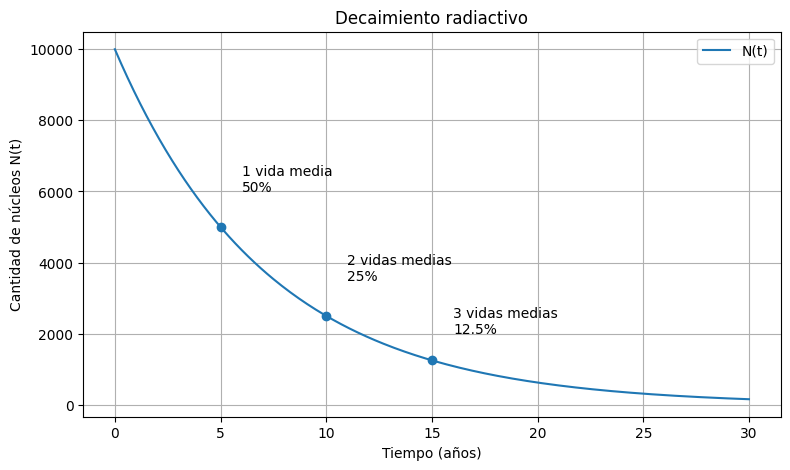

In [20]:
# 4: Gráfica del decaimiento radiactivo ---

plt.figure(figsize=(9, 5))  # Define el tamaño de la figura en pulgadas.

plt.plot(t, N, label="N(t)")  # Grafica la cantidad de núcleos en función del tiempo.

# Marcar 1, 2 y 3 vidas medias
tiempos_half = np.array([5, 10, 15])  # Crea un arreglo con los tiempos correspondientes a tres vidas medias.
valores_half = N_decaimiento(tiempos_half)  # Calcula los núcleos restantes en esos tiempos.

plt.scatter(tiempos_half, valores_half, zorder=3)  # Marca los puntos de las vidas medias sobre la curva.

# Etiquetas de los puntos
plt.annotate("1 vida media\n50%", (5, 5000),
             xytext=(6, 6000))  # Añade una etiqueta al punto de una vida media.

plt.annotate("2 vidas medias\n25%", (10, 2500),
             xytext=(11, 3500))  # Añade una etiqueta al punto de dos vidas medias.

plt.annotate("3 vidas medias\n12.5%", (15, 1250),
             xytext=(16, 2000))  # Añade una etiqueta al punto de tres vidas medias.

plt.title("Decaimiento radiactivo")  # Establece el título de la gráfica.
plt.xlabel("Tiempo (años)")  # Identifica el eje horizontal y su unidad.
plt.ylabel("Cantidad de núcleos N(t)")  # Identifica el eje vertical.
plt.grid(True)  # Activa la cuadrícula para facilitar la lectura de los valores.
plt.legend()  # Muestra la leyenda de la curva.

plt.show()  # Genera y muestra la gráfica.



La gráfica muestra el decaimiento exponencial de la muestra. Se observa que la cantidad de núcleos disminuye con el tiempo y que después de cada vida media queda el 50 % de la cantidad existente al inicio de ese intervalo.


**5. Identifique sobre la gráfica los tiempos correspondientes a **una, dos y tres vidas medias**. Observe qué fracción de la muestra permanece después de cada una de ellas.**

1 vida(s) media(s):
  Fracción restante: 0.500 (50.0%)
  Tiempo: 5.0000 años

2 vida(s) media(s):
  Fracción restante: 0.250 (25.0%)
  Tiempo: 10.0000 años

3 vida(s) media(s):
  Fracción restante: 0.125 (12.5%)
  Tiempo: 15.0000 años



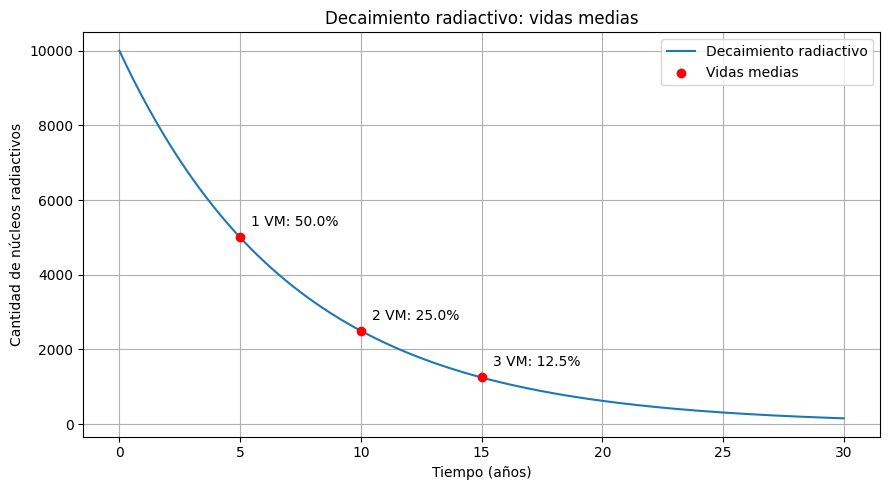

In [21]:

#Tiempos correspondientes a una, dos y tres vidas medias ---

# Definir las fracciones de la muestra que permanecen después de cada
# vida media: 50 %, 25 % y 12.5 %, respectivamente.
fracciones = [0.50, 0.25, 0.125]

# Calcular el tiempo necesario para alcanzar cada fracción.
# Se despeja t de la ecuación N(t)/N0 = exp(-lam*t):
# t = -ln(f)/lam, donde f es la fracción restante.
for i, f in enumerate(fracciones, start=1):
    tiempo = -np.log(f) / lam

    # Mostrar el número de vidas medias, la fracción restante
    # en porcentaje y el tiempo correspondiente en años.
    print(f"{i} vida(s) media(s):")
    print(f"  Fracción restante: {f:.3f} ({f*100:.1f}%)")
    print(f"  Tiempo: {tiempo:.4f} años\n")

# Calcular los tiempos y las cantidades restantes para identificar
# gráficamente los puntos correspondientes a cada vida media.
tiempos_vm = [-np.log(f) / lam for f in fracciones]
cantidades_vm = [N0 * f for f in fracciones]

# Representar nuevamente el decaimiento radiactivo e incluir
# los puntos correspondientes a una, dos y tres vidas medias.
plt.figure(figsize=(9, 5))
plt.plot(t, N, label="Decaimiento radiactivo")

# Marcar las cantidades restantes en los tiempos calculados.
plt.scatter(tiempos_vm, cantidades_vm, color="red",
            zorder=3, label="Vidas medias")

# Añadir etiquetas para identificar cada punto y su porcentaje.
for i, (tiempo, cantidad, f) in enumerate(
    zip(tiempos_vm, cantidades_vm, fracciones), start=1
):
    plt.annotate(
        f"{i} VM: {f*100:.1f}%",
        (tiempo, cantidad),
        xytext=(8, 8),
        textcoords="offset points"
    )

# Configurar el título, los ejes, la cuadrícula y la leyenda.
plt.title("Decaimiento radiactivo: vidas medias")
plt.xlabel("Tiempo (años)")
plt.ylabel("Cantidad de núcleos radiactivos")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Los resultados muestran que la cantidad de núcleos radiactivos disminuye exponencialmente con el tiempo. Después de una, dos y tres vidas medias (5, 10 y 15 años), permanece el 50 %, 25 % y 12,5 % de la muestra inicial, respectivamente. Esto confirma que la cantidad de núcleos se reduce a la mitad en cada vida media, tal como predice el modelo de decaimiento radiactivo.



**6. Determine aproximadamente el tiempo en el cual permanece:**

   **- el **50 %** de la muestra inicial;**

   **- el **25 %** de la muestra inicial;**

   **- el **10 %** de la muestra inicial.**

In [22]:

#Tiempo necesario para alcanzar ciertas fracciones de la muestra ---

# Definir las fracciones de la muestra inicial que se desean analizar:
# 50 %, 25 % y 10 %.
fracciones_objetivo = [0.50, 0.25, 0.10]

# Calcular el tiempo necesario para alcanzar cada fracción.
# A partir del modelo N(t) = N0*exp(-lam*t), se despeja:
# t = -ln(f)/lam, donde f = N(t)/N0.
for f in fracciones_objetivo:
    tiempo = -np.log(f) / lam

    # Mostrar la fracción objetivo y el tiempo calculado en años.
    print(
        f"{f*100:.0f}% de la cantidad inicial: "
        f"{tiempo:.4f} años"
    )

50% de la cantidad inicial: 5.0000 años
25% de la cantidad inicial: 10.0000 años
10% de la cantidad inicial: 16.6096 años


Los resultados indican que la muestra tarda 5 años en reducirse al 50 %, 10 años en alcanzar el 25 % y aproximadamente 16,61 años en llegar al 10 % de su cantidad inicial. Esto confirma el comportamiento exponencial del decaimiento radiactivo, en el cual la cantidad de núcleos disminuye progresivamente con el tiempo.

**PARTE C. VERIFICACIÓN PASS/FAIL**

In [24]:

# --- Parte B: complete N_decaimiento y luego corra la verificación ---

import math

def N_decaimiento(t, N0=10000, t_half=5.0):
    # Calcula la constante de decaimiento
    lam = math.log(2) / t_half

    # Modelo de decaimiento radiactivo
    return N0 * math.exp(-lam * t)


casos_b = [
    (0.0, 1.00),    # En t=0 debe quedar el 100% de la muestra.
    (5.0, 0.50),    # Una vida media: queda el 50%.
    (10.0, 0.25),   # Dos vidas medias: queda el 25%.
]

for t, fraccion_esperada in casos_b:
    try:
        obtenido = N_decaimiento(t) / 10000

        ok = abs(obtenido - fraccion_esperada) < 1e-3
        estado = "PASS" if ok else "FAIL"

        print(
            f"{estado}  t={t:>5.1f} años   "
            f"fraccion={obtenido:.3f}   "
            f"esperada={fraccion_esperada:.3f}"
        )

    except NotImplementedError as e:
        print(f"FAIL  t={t:>5.1f} años   ({e})")

PASS  t=  0.0 años   fraccion=1.000   esperada=1.000
PASS  t=  5.0 años   fraccion=0.500   esperada=0.500
PASS  t= 10.0 años   fraccion=0.250   esperada=0.250


****